# 07 Ereduak esportatu eta Jetson Nanon hedatu

Jetson Nanok JetPack 4.6 du (Ubuntu 18.04 eta Python 3.6). Han ezin dira kargatu PCan scikit-learn 1.x-ekin gordetako .joblib fitxategiak, eta TensorFlow instalatzea luzea eta astuna da.

Horregatik ereduak fitxategi sinpleetara esportatzen ditugu (parametroak JSONean eta sarearen pisuak .npz-n) eta Jetsonen numpy-rekin bakarrik exekutatzen ditugu, jetson/sistema.py moduluarekin:

| Eredua | Zer esportatzen den | Nola exekutatzen den |
|---|---|---|
| Aurreprozesamendua | Medianak, batez bestekoak, desbideratzeak eta kategoriak | Estandarizatu eta 0/1 zutabeak sortu |
| MLPa (06) | Geruza bakoitzaren pisuak (.npz) | Matrize-biderketa + ReLU |
| Erabaki-zuhaitza (04) | Nodoak eta atalaseak | Zuhaitzean behera joan |
| K-means (05) | Prestaketa eta zentroideak | Zentroide hurbilena bilatu |

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import warnings
warnings.filterwarnings("ignore")

import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

sys.path.append("../jetson")
import sistema

sns.set_theme(style="whitegrid")

I0000 00:00:1795087850.507963     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795087850.565308     168 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795087867.906932     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795087867.909989     168 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. PCan entrenatutako ereduak kargatu

In [2]:
aurreprozesadorea = joblib.load("../ereduak/aurreprozesadorea.joblib")
ALDAGAIAK = joblib.load("../ereduak/sarrera_aldagaiak.joblib")
zuhaitz_pipeline = joblib.load("../ereduak/sailkapen_onena_zuhaitza.joblib")
kmeans_pipeline = joblib.load("../ereduak/kmeans_egoerak.joblib")
kmeans_info = joblib.load("../ereduak/kmeans_info.joblib")
mlp = tf.keras.models.load_model("../ereduak/mlp_erregresioa_NO2.keras")

print("Sarrerako aldagaiak:", len(ALDAGAIAK))
print("K-means egoerak:", kmeans_info["izenak"])

Sarrerako aldagaiak: 18
K-means egoerak: {2: 'Partikula-episodioa', 0: 'Trafikoko puntako ordua', 3: 'Aire garbia haizearekin', 1: 'Gaueko bareta'}


## 2. Parametroak atera

### 2.1 Aurreprozesamendua

In [3]:
eraldatzailea = aurreprozesadorea.named_steps["eraldatu"]
numerikoak = eraldatzailea.named_transformers_["numerikoak"]
kategorikoak = eraldatzailea.named_transformers_["kategorikoak"]

aurreprozesamendu_parametroak = {
    "numerikoak": list(eraldatzailea.transformers_[0][2]),
    "medianak": numerikoak.named_steps["inputatu"].statistics_.tolist(),
    "batez_bestekoak": numerikoak.named_steps["eskalatu"].mean_.tolist(),
    "eskalak": numerikoak.named_steps["eskalatu"].scale_.tolist(),
    "kategorikoak": list(eraldatzailea.transformers_[1][2]),
    "maizenak": [float(v) for v in kategorikoak.named_steps["inputatu"].statistics_],
    "kategoriak": [[float(k) for k in zerrenda] for zerrenda in kategorikoak.named_steps["onehot"].categories_],
}
print("Numerikoak:", len(aurreprozesamendu_parametroak["numerikoak"]))
print("Kategorikoak:", aurreprozesamendu_parametroak["kategorikoak"])
print("Kategoria kopurua:", [len(k) for k in aurreprozesamendu_parametroak["kategoriak"]])

Numerikoak: 14
Kategorikoak: ['ordua', 'aste_eguna', 'hilabetea', 'haize_sektorea']
Kategoria kopurua: [24, 7, 12, 8]


### 2.2 Erabaki-zuhaitza

In [4]:
zuhaitza = zuhaitz_pipeline.named_steps["eredua"]
nodoak = zuhaitza.tree_
zutabe_izenak = [n.split("__")[1] for n in zuhaitz_pipeline.named_steps["aurreprozesamendua"].named_steps["eraldatu"].get_feature_names_out()]

zuhaitz_parametroak = {
    "ezkerra": nodoak.children_left.tolist(),
    "eskuina": nodoak.children_right.tolist(),
    "aldagaia": nodoak.feature.tolist(),
    "atalasea": nodoak.threshold.tolist(),
    # Nodo bakoitzaren klasea: nodo horretan ordu gehien dituena
    "klasea": [str(zuhaitza.classes_[np.argmax(v)]) for v in nodoak.value[:, 0, :]],
    "zutabe_izenak": zutabe_izenak,
}
print("Zuhaitzaren nodoak:", nodoak.node_count, "| hostoak:", zuhaitza.get_n_leaves(), "| sakonera:", zuhaitza.get_depth())

Zuhaitzaren nodoak: 31 | hostoak: 16 | sakonera: 4


In [ ]:
# Zuhaitzaren aurreprozesadorea PIAkoaren berdina dela egiaztatzen dugu
zuhaitz_aurre = zuhaitz_pipeline.named_steps["aurreprozesamendua"]
X_a = zuhaitz_aurre.transform(pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data")[ALDAGAIAK].head(200))
X_b = aurreprozesadorea.transform(pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data")[ALDAGAIAK].head(200))
print("Bi aurreprozesadoreen arteko alde maximoa:", np.abs(X_a - X_b).max())

Bi aurreprozesadoreen arteko alde maximoa: 0.0


### 2.3 K-means

In [6]:
prestaketa = kmeans_pipeline.named_steps["prestaketa"]
kmeans = kmeans_pipeline.named_steps["kmeans"]

kmeans_parametroak = {
    "aldagaiak": kmeans_info["aldagaiak"],
    "medianak": prestaketa.named_steps["inputatu"].statistics_.tolist(),
    "batez_bestekoak": prestaketa.named_steps["eskalatu"].mean_.tolist(),
    "eskalak": prestaketa.named_steps["eskalatu"].scale_.tolist(),
    "zentroideak": kmeans.cluster_centers_.tolist(),
    "izenak": {str(k): v for k, v in kmeans_info["izenak"].items()},
}
kmeans_parametroak["izenak"]

{'2': 'Partikula-episodioa',
 '0': 'Trafikoko puntako ordua',
 '3': 'Aire garbia haizearekin',
 '1': 'Gaueko bareta'}

### 2.4 Gorde

MLPa 06 koadernoan esportatu genuen (mlp_erregresioa_NO2_pisuak.npz eta .tflite).

In [ ]:
parametroak = {
    "deskribapena": "Barakaldoko airearen kalitate-sistemaren ereduak",
    "aurreprozesamendua": aurreprozesamendu_parametroak,
    "zuhaitza": zuhaitz_parametroak,
    "kmeans": kmeans_parametroak,
}
with open("../jetson/ereduak/parametroak.json", "w", encoding="utf-8") as fitxategia:
    json.dump(parametroak, fitxategia, ensure_ascii=False, indent=1)

for izena in sorted(os.listdir("../jetson/ereduak")):
    print(izena, "->", round(os.path.getsize("../jetson/ereduak/" + izena) / 1024, 1), "KB")

mlp_erregresioa_NO2.tflite -> 26.7 KB
mlp_erregresioa_NO2_pisuak.npz -> 26.2 KB
parametroak.json -> 6.4 KB


## 3. Denbora errealeko simulaziorako datuak

Estazioarekin zuzeneko konexiorik ez dugunez, 2026ko datuekin simulatzen dugu: Jetsoneko programak orduz ordu irakurtzen ditu, iristen joango balira bezala.

In [8]:
proba = pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data", parse_dates=True)
zutabeak = ALDAGAIAK + ["NO2_hurrengoa", "ICA_estazioa", "ICA_hurrengoa"]

os.makedirs("../jetson/datuak", exist_ok=True)
simulazioa = proba[zutabeak].copy()
simulazioa.index = simulazioa.index.strftime("%Y-%m-%d %H:%M")
simulazioa.to_csv("../jetson/datuak/simulazioa_2026.csv", index_label="data")
print("Gordeta jetson/datuak/simulazioa_2026.csv:", simulazioa.shape,
      "|", round(os.path.getsize("../jetson/datuak/simulazioa_2026.csv") / 1024), "KB")

Gordeta jetson/datuak/simulazioa_2026.csv: (7253, 21) | 959 KB


## 4. Egiaztapena

Sistema Jetsonek bezala kargatzen dugu (sistema.py + esportatutako fitxategiak) eta 2026ko ordu guztietan jatorrizko ereduekin alderatzen dugu.

In [ ]:
sis = sistema.sistema_kargatu("../jetson/ereduak", motorra="numpy")
datuak = sistema.datuak_irakurri("../jetson/datuak/simulazioa_2026.csv")

no2_jetson, ica_jetson, egoera_jetson = [], [], []
for errenkada in datuak:
    x = sistema.aurreprozesatu(errenkada, sis)
    no2_jetson.append(sistema.no2_iragarri(x, sis))
    ica_jetson.append(sistema.ica_sailkatu(x, sis))
    egoera_jetson.append(sistema.ingurumen_egoera(errenkada, sis))

#Jatorrizko iragarpenak
X_proba = aurreprozesadorea.transform(proba[ALDAGAIAK]).astype("float32")
no2_jatorrizkoa = mlp.predict(X_proba, verbose=0).ravel()
ica_jatorrizkoa = zuhaitz_pipeline.predict(proba[ALDAGAIAK])
egoera_jatorrizkoa = [kmeans_info["izenak"][c] for c in kmeans_pipeline.predict(proba[kmeans_info["aldagaiak"]])]

print("Aurreprozesamendua - alde maximoa:", np.abs(np.array([sistema.aurreprozesatu(e, sis) for e in datuak[:500]]) - X_proba[:500]).max())
print("MLP                - alde maximoa:", round(float(np.abs(np.array(no2_jetson) - no2_jatorrizkoa).max()), 6), "µg/m³")
print("Zuhaitza           - bat-etortzea:", round(100 * np.mean(np.array(ica_jetson) == ica_jatorrizkoa), 2), "%")
print("K-means            - bat-etortzea:", round(100 * np.mean(np.array(egoera_jetson) == np.array(egoera_jatorrizkoa)), 2), "%")

Aurreprozesamendua - alde maximoa: 0.0
MLP                - alde maximoa: 8e-06 µg/m³
Zuhaitza           - bat-etortzea: 100.0 %
K-means            - bat-etortzea: 100.0 %


Esportatutako sistemak emaitza berberak ematen ditu: MLParen aldea µg/m³-ren milarenetan dago (biribiltzea), eta zuhaitza eta K-means orduen % 100ean datoz bat.

## 5. Inferentzia-denborak PCan

Modu bakoitzak ordu bat prozesatzeko zenbat behar duen neurtzen dugu (sistemak denbora errealean egingo duena), 1.000 aldiz errepikatuta.

In [10]:
def neurtu(funtzioa, errepikapenak=1000):
    for _ in range(20):
        funtzioa()
    denborak = []
    for _ in range(errepikapenak):
        hasiera = time.perf_counter()
        funtzioa()
        denborak.append((time.perf_counter() - hasiera) * 1000)
    return np.mean(denborak), np.percentile(denborak, 95)

errenkada = datuak[100]
errenkada_df = proba[ALDAGAIAK].iloc[[100]]
x = sistema.aurreprozesatu(errenkada, sis)
x_keras = X_proba[[100]]
sis_tflite = sistema.sistema_kargatu("../jetson/ereduak", motorra="tflite")

probak = [
    ("MLP Kerasekin (model.predict)", lambda: mlp.predict(x_keras, verbose=0), 200),
    ("MLP Kerasekin (dei zuzena)", lambda: mlp(x_keras, training=False), 500),
    ("MLP TensorFlow Lite-rekin", lambda: sistema.no2_iragarri(x, sis_tflite), 1000),
    ("MLP numpy-rekin", lambda: sistema.no2_iragarri(x, sis), 1000),
    ("Zuhaitza scikit-learn-ekin (Pipeline)", lambda: zuhaitz_pipeline.predict(errenkada_df), 500),
    ("Zuhaitza numpy-rekin", lambda: sistema.ica_sailkatu(x, sis), 1000),
    ("K-means numpy-rekin", lambda: sistema.ingurumen_egoera(errenkada, sis), 1000),
    ("Sistema osoa numpy-rekin (ordu 1)", lambda: sistema.ordua_prozesatu(errenkada, sis), 1000),
]

errenkadak = []
for izena, funtzioa, errepikapenak in probak:
    batez_bestekoa, p95 = neurtu(funtzioa, errepikapenak)
    errenkadak.append([izena, batez_bestekoa, p95])
    print(izena, "->", round(batez_bestekoa, 4), "ms")

pc_denborak = pd.DataFrame(errenkadak, columns=["proba", "batez bestekoa (ms)", "p95 (ms)"])
pc_denborak.round(4)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


MLP Kerasekin (model.predict) -> 53.7596 ms


MLP Kerasekin (dei zuzena) -> 2.2792 ms
MLP TensorFlow Lite-rekin -> 0.0115 ms
MLP numpy-rekin -> 0.0059 ms


Zuhaitza scikit-learn-ekin (Pipeline) -> 5.3815 ms
Zuhaitza numpy-rekin -> 0.0013 ms
K-means numpy-rekin -> 0.0165 ms
Sistema osoa numpy-rekin (ordu 1) -> 0.043 ms


,proba,batez bestekoa (ms),p95 (ms)
0,MLP Kerasekin (model.predict),53.7596,65.4679
1,MLP Kerasekin (dei zuzena),2.2792,2.5955
2,MLP TensorFlow Lite-rekin,0.0115,0.0134
3,MLP numpy-rekin,0.0059,0.0060
4,Zuhaitza scikit-learn-ekin (Pipeline),5.3815,7.3236
5,Zuhaitza numpy-rekin,0.0013,0.0013
6,K-means numpy-rekin,0.0165,0.0253
7,Sistema osoa numpy-rekin (ordu 1),0.0430,0.0631


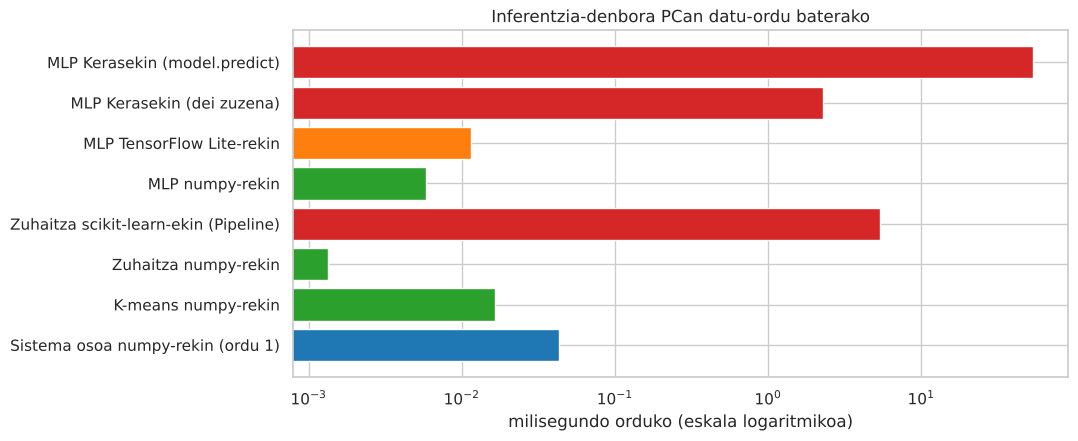

In [11]:
plt.figure(figsize=(10, 4.5))
plt.barh(pc_denborak["proba"], pc_denborak["batez bestekoa (ms)"],
         color=["tab:red", "tab:red", "tab:orange", "tab:green", "tab:red", "tab:green", "tab:green", "tab:blue"])
plt.xscale("log")
plt.xlabel("milisegundo orduko (eskala logaritmikoa)")
plt.title("Inferentzia-denbora PCan datu-ordu baterako")
plt.gca().invert_yaxis()
plt.show()

pc_denborak.to_csv("../docs/denborak_pc.csv", index=False)

Kerasen model.predict() oso motela da ordu bakar baterako (50-60 ms), dei bakoitzean prestaketa asko egiten duelako. TensorFlow Litek 0,01 ms behar ditu eta numpy-k are gutxiago. scikit-learn-en Pipeline-arekin berdin gertatzen da zuhaitzarekin: 5 ms, numpy-rekin 0,001 ms baino ez.

Sistema osoak (aurreprozesamendua + hiru ereduak) 0,04 ms behar ditu ordu bakoitzeko PCan. Jetson Nanoa motelagoa da, baina ordu bakoitzeko datu bat iristen denez, ez da arazo izango. Jetsonen denborak_neurtu.py-rekin neurtu dugu: sistema osoak 0,54 ms behar ditu orduko, PCan baino 13 aldiz gehiago, baina segundoko 1.800 ordu prozesatzeko adina.

## 6. Optimizazioa  kuantizazioa

Kuantizatzea sarearen pisuak bit gutxiagorekin gordetzea da: 32 biteko zenbaki hamartarren (float32) ordez, 8 biteko osokoak (int8). Eredua txikiagoa da eta gailu batzuetan azkarragoa, baina zehaztasun pixka bat gal daiteke. TensorFlow Litek berak egiten du, bihurtzean aukera bat gehituta.

In [12]:
# MLPa int8ra kuantizatu eta jatorrizko .tflite-arekin alderatu (sistema.py erabiliz, Jetsonen bezala)
bihurgailua = tf.lite.TFLiteConverter.from_keras_model(mlp)
bihurgailua.optimizations = [tf.lite.Optimize.DEFAULT]   # pisuak int8ra
bihurgailua._experimental_disable_per_channel_quantization_for_dense_layers = True   # eskala bakarra geruzako: Jetsoneko tflite_runtime zaharrak ez du kanal bakoitzekoa onartzen
with open("../jetson/ereduak/mlp_erregresioa_NO2_int8.tflite", "wb") as fitxategia:
    fitxategia.write(bihurgailua.convert())

y_benetakoa = proba["NO2_hurrengoa"].values
x_orduak = [sistema.aurreprozesatu(e, sis) for e in datuak]

errenkadak = []
for izena, fitxategia in [("float32 (jatorrizkoa)", "mlp_erregresioa_NO2.tflite"),
                          ("int8 (kuantizatua)", "mlp_erregresioa_NO2_int8.tflite")]:
    sis_bertsioa = sistema.sistema_kargatu("../jetson/ereduak", motorra="tflite", tflite_fitxategia=fitxategia)
    iragarpena = np.array([sistema.no2_iragarri(x_ordua, sis_bertsioa) for x_ordua in x_orduak])
    denbora, _ = neurtu(lambda: sistema.no2_iragarri(x, sis_bertsioa))
    errenkadak.append([izena,
                       round(os.path.getsize("../jetson/ereduak/" + fitxategia) / 1024, 1),
                       round(np.abs(iragarpena - y_benetakoa).mean(), 3),
                       round(np.abs(iragarpena - no2_jatorrizkoa).max(), 3),
                       round(denbora, 4)])

kuantizazioa = pd.DataFrame(errenkadak, columns=["bertsioa", "tamaina (KB)", "MAE 2026",
                                                 "alde max. Kerasekin", "denbora (ms)"])
kuantizazioa

INFO:tensorflow:Assets written to: /tmp/tmpq9uvcgsh/assets


INFO:tensorflow:Assets written to: /tmp/tmpq9uvcgsh/assets


Saved artifact at '/tmp/tmpq9uvcgsh'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 65), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140034533407056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034533408016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034533407248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034533408592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034533408208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140034533016784: TensorSpec(shape=(), dtype=tf.resource, name=None)


,bertsioa,tamaina (KB),MAE 2026,alde max. Kerasekin,denbora (ms)
0,float32 (jatorrizkoa),26.7,4.116,0.000,0.0161
1,int8 (kuantizatua),8.6,4.116,0.671,0.0157


- int8 bertsioak ia 3 aldiz gutxiago betetzen du (27 KBtik 9 KBra) eta MAE ez da aldatzen (4,116). Iragarpena gehienez 0,7 µg/m³ urruntzen da jatorrizkotik. Geruza bakoitzeko eskala bakarra erabiltzen dugu (ez kanal bakoitzeko bat), Jetsoneko tflite_runtime zaharrak ez duelako bestea onartzen.
- PCan denbora berdina da: sarea hain txikia da, ezen denbora ia guztia interpretatzaileari deia egiten joaten da.
- Jetson Nanoak 4 GB RAM ditu eta 27 KB ez dira arazo bat; horregatik sistemak numpy erabiltzen jarraitzen du lehenetsita. Kuantizazioa erabilgarria izango litzateke eredu handiagoekin edo memoria gutxiko gailuetan. int8 bertsioa prest geratzen da (python3 sistema_exekutatu.py --motorra tflite --tflite mlp_erregresioa_NO2_int8.tflite), eta denborak_neurtu.py-k Jetsonen ere neurtzen du: 0,116 ms, float32 bertsioak bezala (0,115 ms).

## 7. Urratsak Jetson Nanon

Argibideak jetson/JETSON_README.md fitxategian daude. Laburbilduz: jetson karpeta kopiatu, bash instalatu.sh exekutatu, eta gero python3 denborak_neurtu.py eta python3 sistema_exekutatu.py.